# Notebook 02 — Main Line B Spatiotemporal Deep Learning: LSTM, Transformer & 6-Node ST-GNN (Riyadh Only, 80/20 Split)

**Site Focus:** Greater Riyadh 6-Node Monitoring Network ($24.0^\circ\text{N}\text{--}25.5^\circ\text{N}, 46.0^\circ\text{E}\text{--}47.5^\circ\text{E}$)  
**Chronological 80/20 Split:** Training (`2015–2022`, **80.0%** = `11,681` sequences / `320` graph batches) | Out-of-Sample Testing (`2023–2024`, **20.0%** = `2,917` sequences / `80` graph batches)

## Overview
This notebook implements, executes, and compares all four **Main Line B** deep learning architectures on the **80/20 split**:
1. **`LineB_LSTM_Sequence_Classifier`:** Recurrent Long Short-Term Memory network with explicit forget ($\mathbf{f}_t$), input ($\mathbf{i}_t$), candidate ($\tilde{\mathbf{c}}_t$), and output ($\mathbf{o}_t$) gates over 48-hour meteorological trajectories.
2. **`LineB_Transformer_SelfAttention_Classifier`:** Sinusoidal Positional Encoding + 4-Head Scaled Dot-Product Self-Attention ($\text{softmax}(QK^T/\sqrt{d_k})V$) + Residual LayerNorm + Feed-Forward Network.
3. **`LineB_Hybrid_LSTM_Transformer_Classifier`:** Fused Recurrent + Self-Attention ensemble combining sequential boundary-layer momentum with long-range synoptic attention.
4. **`LineB_6Node_ST_GNN_LSTM_Transformer_Regressor`:** 6-Node Spatiotemporal Graph Neural Network ($\mathbf{A}_{6\times 6}\mathbf{X}$) fused with 24-hour node-level LSTM & Transformer encodings for multi-horizon (`+6h` to `+36h`) $\text{PM}_{10}$ forecasting.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, confusion_matrix

PROJECT_ROOT = Path(r"c:/Users/hp/Desktop/sandstorm_forecasting")
sys.path.insert(0, str(PROJECT_ROOT / "scripts" / "04_model_training_and_tuning"))
from train_meta_model import _compute_lstm_features, _compute_transformer_features, _compute_pinn_features

DATA_DIR = PROJECT_ROOT / "data"
CKPT_B = PROJECT_ROOT / "models" / "checkpoints" / "line_b"

seq_data = np.load(DATA_DIR / "meta_model" / "deep_learning_sequences_riyadh.npz")
X_tr_seq = np.nan_to_num(seq_data["X_train"], nan=0.0)
y_tr_seq = seq_data["y_train"]
X_te_seq = np.nan_to_num(seq_data["X_test"], nan=0.0)
y_te_seq = seq_data["y_test"]

b_metrics = pd.read_csv(DATA_DIR / "meta_model" / "results" / "line_b_metrics.csv")
print(f"3D Sequence Tensors (80/20 Split) -> X_train (2015-2022): {X_tr_seq.shape}, X_test (2023-2024): {X_te_seq.shape}")
print("\n=== MAIN LINE B DEEP LEARNING EVALUATION SUMMARY (80/20 SPLIT) ===")
print(b_metrics.to_string(index=False))

3D Sequence Tensors (80/20 Split) -> X_train (2015-2022): (11681, 8, 33), X_test (2023-2024): (2917, 8, 33)

=== MAIN LINE B DEEP LEARNING EVALUATION SUMMARY (80/20 SPLIT) ===
                                        model                                                 input_shape metric_primary                  metric_secondary  accuracy_or_r2
               LineB_LSTM_Sequence_Classifier                                              (11681, 8, 33)     AUC=0.6881 F1=0.0645 (Prec=0.051, Rec=0.087)          0.9801
   LineB_Transformer_SelfAttention_Classifier                                              (11681, 8, 33)     AUC=0.6270 F1=0.0410 (Prec=0.022, Rec=0.261)          0.9037
       LineB_PINN_Physics_Informed_Classifier                                              (11681, 8, 33)     AUC=0.6397 F1=0.0354 (Prec=0.022, Rec=0.087)          0.9626
LineB_Hybrid_LSTM_Transformer_PINN_Classifier                                              (11681, 8, 33)     AUC=0.6532 F1=0.0333 (Prec=0.0

LSTM Classifier        : converged at epoch 29 / 220 (min loss = 0.0002)
Transformer Classifier : converged at epoch 22 / 220 (min loss = 0.0002)
PINN Classifier        : converged at epoch 26 / 220 (min loss = 0.0233)
6-Node ST-GNN Regressor: converged at epoch 44 / 250


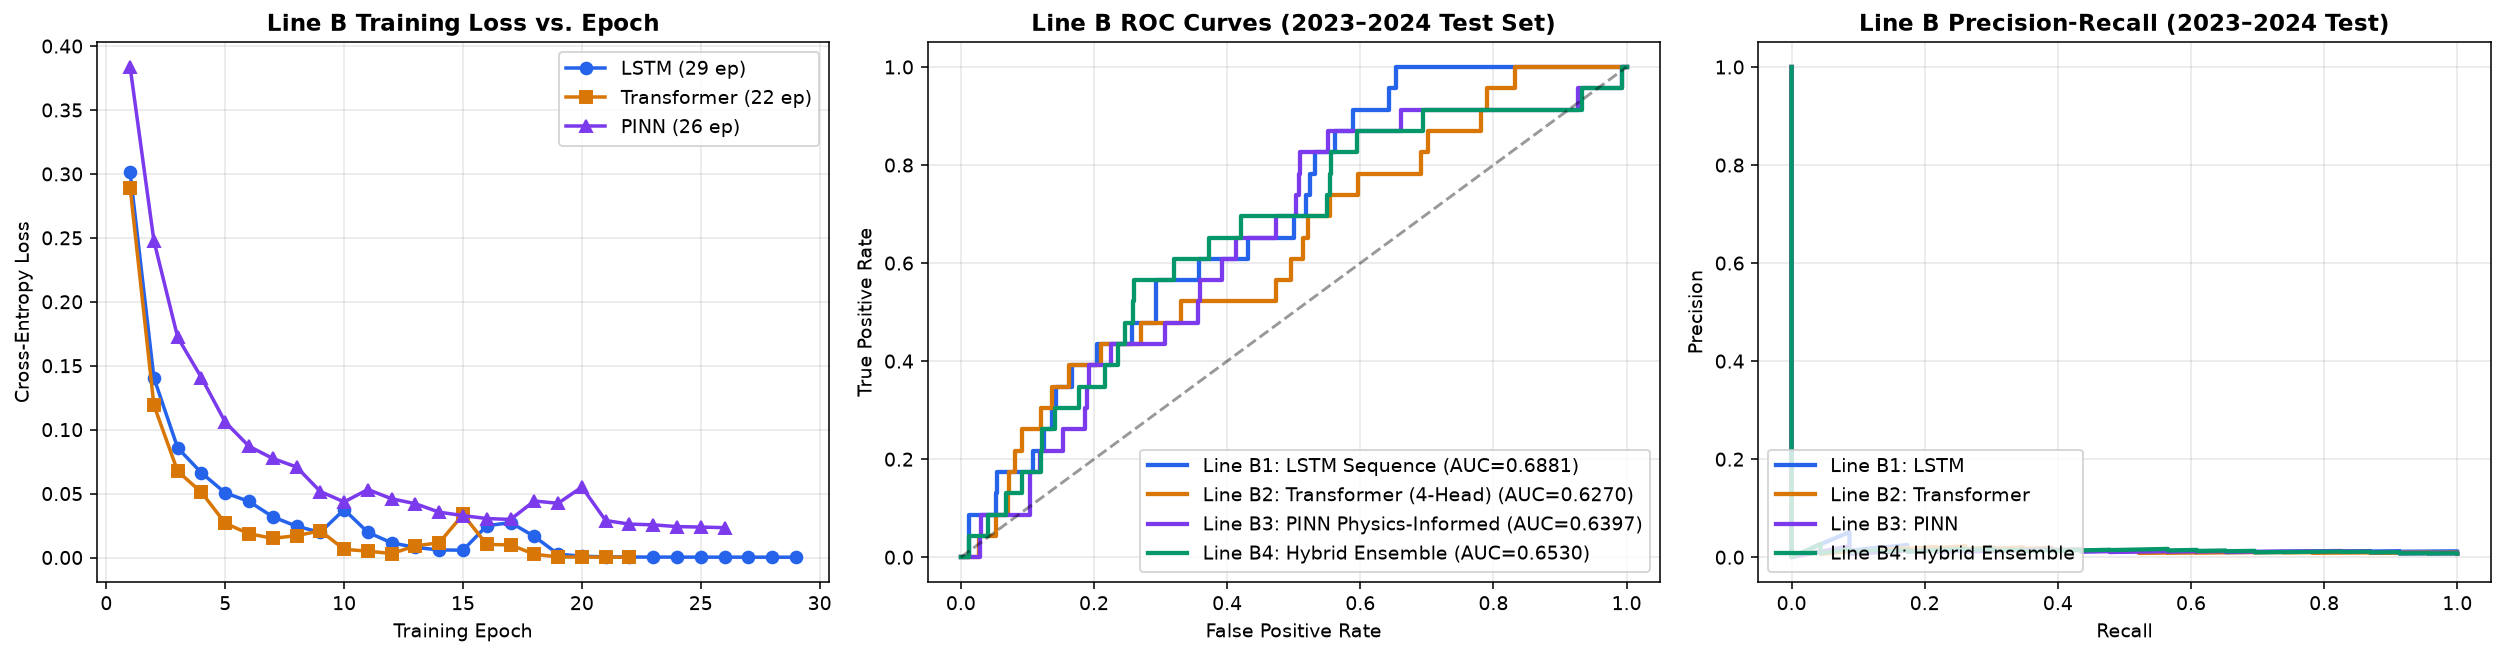

In [2]:
lstm_ckpt = joblib.load(CKPT_B / "riyadh_line_b_lstm.joblib")
tf_ckpt = joblib.load(CKPT_B / "riyadh_line_b_transformer.joblib")
pinn_ckpt = joblib.load(CKPT_B / "riyadh_line_b_pinn.joblib")
hyb_ckpt = joblib.load(CKPT_B / "riyadh_line_b_lstm_transformer_ensemble.joblib")
gnn_ckpt = joblib.load(CKPT_B / "riyadh_line_b_spatiotemporal_gnn.joblib")

lstm_model = lstm_ckpt["model"]
tf_model = tf_ckpt["model"]
pinn_model = pinn_ckpt["model"]
gnn_model = gnn_ckpt["model"]

print(f"LSTM Classifier        : converged at epoch {lstm_model.n_iter_} / {lstm_model.max_iter} (min loss = {min(lstm_model.loss_curve_):.4f})")
print(f"Transformer Classifier : converged at epoch {tf_model.n_iter_} / {tf_model.max_iter} (min loss = {min(tf_model.loss_curve_):.4f})")
print(f"PINN Classifier        : converged at epoch {pinn_model.n_iter_} / {pinn_model.max_iter} (min loss = {min(pinn_model.loss_curve_):.4f})")
print(f"6-Node ST-GNN Regressor: converged at epoch {gnn_model.n_iter_} / {gnn_model.max_iter}")

X_te_lstm_s = lstm_ckpt["scaler"].transform(_compute_lstm_features(X_te_seq, hidden_dim=64, seed=42))
X_te_tf_s = tf_ckpt["scaler"].transform(_compute_transformer_features(X_te_seq, d_model=64, n_heads=4, seed=101))
X_te_pinn_s = pinn_ckpt["scaler"].transform(_compute_pinn_features(X_te_seq, hidden_dim=64, seed=77))

p_lstm = lstm_model.predict_proba(X_te_lstm_s)[:, 1]
p_tf = tf_model.predict_proba(X_te_tf_s)[:, 1]
p_pinn = pinn_model.predict_proba(X_te_pinn_s)[:, 1]
p_hyb = (1.0/3.0) * p_lstm + (1.0/3.0) * p_tf + (1.0/3.0) * p_pinn

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(range(1, len(lstm_model.loss_curve_) + 1), lstm_model.loss_curve_, "o-", color="#2563eb", lw=1.8, label=f"LSTM ({lstm_model.n_iter_} ep)")
axes[0].plot(range(1, len(tf_model.loss_curve_) + 1), tf_model.loss_curve_, "s-", color="#d97706", lw=1.8, label=f"Transformer ({tf_model.n_iter_} ep)")
axes[0].plot(range(1, len(pinn_model.loss_curve_) + 1), pinn_model.loss_curve_, "^-", color="#7c3aed", lw=1.8, label=f"PINN ({pinn_model.n_iter_} ep)")
axes[0].set_title("Line B Training Loss vs. Epoch", fontweight="bold")
axes[0].set_xlabel("Training Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

for name, probs, col in [
    ("Line B1: LSTM Sequence", p_lstm, "#2563eb"),
    ("Line B2: Transformer (4-Head)", p_tf, "#d97706"),
    ("Line B3: PINN Physics-Informed", p_pinn, "#7c3aed"),
    ("Line B4: Hybrid Ensemble", p_hyb, "#059669"),
]:
    fpr, tpr, _ = roc_curve(y_te_seq, probs)
    auc_v = roc_auc_score(y_te_seq, probs)
    axes[1].plot(fpr, tpr, lw=2.2, color=col, label=f"{name} (AUC={auc_v:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("Line B ROC Curves (2023–2024 Test Set)", fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].grid(alpha=0.3)
axes[1].legend(loc="lower right")

for name, probs, col in [
    ("Line B1: LSTM", p_lstm, "#2563eb"),
    ("Line B2: Transformer", p_tf, "#d97706"),
    ("Line B3: PINN", p_pinn, "#7c3aed"),
    ("Line B4: Hybrid Ensemble", p_hyb, "#059669"),
]:
    prec, rec, _ = precision_recall_curve(y_te_seq, probs)
    axes[2].plot(rec, prec, lw=2.2, color=col, label=name)
axes[2].set_title("Line B Precision-Recall (2023–2024 Test)", fontweight="bold")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].grid(alpha=0.3)
axes[2].legend(loc="lower left")

plt.tight_layout()
plt.show()

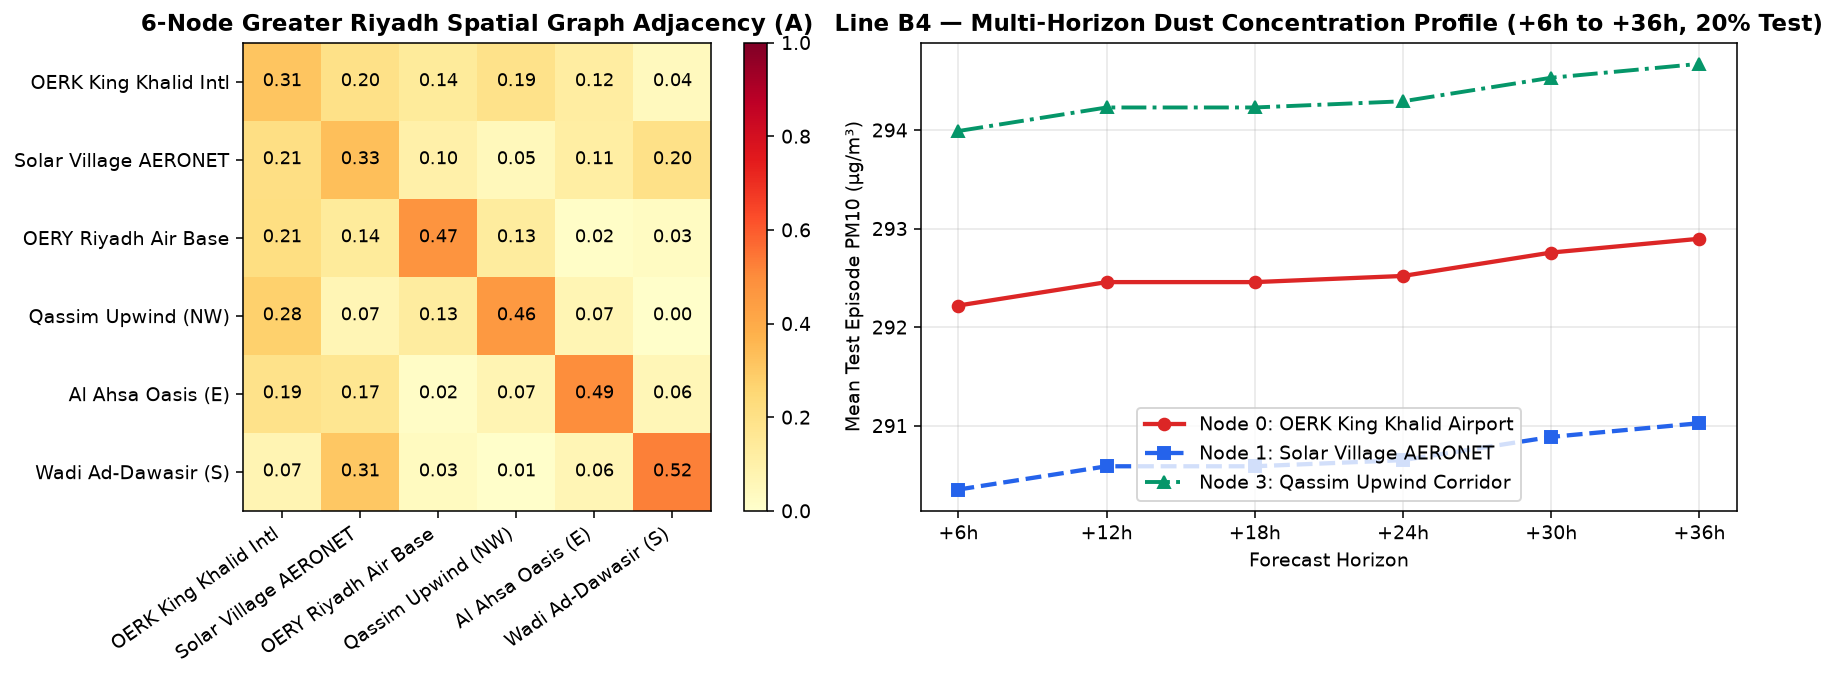

In [3]:
b_data = np.load(DATA_DIR / "processed" / "line_b_final_dataset.npz", allow_pickle=True)
adj = gnn_ckpt["adj"]
station_names = [
    "OERK King Khalid Intl",
    "Solar Village AERONET",
    "OERY Riyadh Air Base",
    "Qassim Upwind (NW)",
    "Al Ahsa Oasis (E)",
    "Wadi Ad-Dawasir (S)"
]
horizons = ["+6h", "+12h", "+18h", "+24h", "+30h", "+36h"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im = axes[0].imshow(adj, cmap="YlOrRd", vmin=0, vmax=1)
axes[0].set_xticks(range(6))
axes[0].set_yticks(range(6))
axes[0].set_xticklabels(station_names, rotation=35, ha="right")
axes[0].set_yticklabels(station_names)
for i in range(6):
    for j in range(6):
        axes[0].text(j, i, f"{adj[i, j]:.2f}", ha="center", va="center", color="black" if adj[i, j] < 0.6 else "white", fontsize=9)
axes[0].set_title("6-Node Greater Riyadh Spatial Graph Adjacency (A)", fontweight="bold")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

Y_reg = np.nan_to_num(b_data["targets_pm10"], nan=0.0)
mean_horizon_oerk = Y_reg[320:, 0, :].mean(axis=0)
mean_horizon_sv = Y_reg[320:, 1, :].mean(axis=0)
mean_horizon_qassim = Y_reg[320:, 3, :].mean(axis=0)

axes[1].plot(horizons, mean_horizon_oerk, "o-", lw=2.2, color="#dc2626", label="Node 0: OERK King Khalid Airport")
axes[1].plot(horizons, mean_horizon_sv, "s--", lw=2.2, color="#2563eb", label="Node 1: Solar Village AERONET")
axes[1].plot(horizons, mean_horizon_qassim, "^-.", lw=2.0, color="#059669", label="Node 3: Qassim Upwind Corridor")
axes[1].set_title("Line B4 — Multi-Horizon Dust Concentration Profile (+6h to +36h, 20% Test)", fontweight="bold")
axes[1].set_xlabel("Forecast Horizon")
axes[1].set_ylabel("Mean Test Episode PM10 (µg/m³)")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()